# LangGraph 기반 Agentic RAG — Step 3. 질문 라우팅 + 답변 근거 검증

— 인공지능기본법 QA

> Agentic RAG : "LLM 판정이 들어간 자기교정형 RAG 워크플로우
> 파이프라인 중간에 LLM이 내리는 자율적 판단/분기/자기교정 지점이 하나 이상 들어가서, 상황에 따라 스스로 경로를 바꾸거나 
> 다시 시도하는 RAG 구조

[1-2.corrective_rag.ipynb](./1-2.corrective_rag.ipynb)에서 만든 검색 평가ㆍ재작성 루프에
그래프의 **입구와 출구**에 판단 노드를 더해 Agentic RAG를 완성한다.

- `route_question` (입구): 인사/잡담/사용법 문의만 `direct_answer`, 나머지는 모두 검색 경로
  (법 범위 밖 질문도 검색 경로로 보내야 LLM이 상식으로 지어내지 않고 `no_evidence`로 끝난다)
- `check_grounded` (출구): 생성된 답변이 검색 조문에 근거했는지 검증. 근거가 없으면 한 번 더 생성 (최대 `MAX_GENERATIONS`회)

> 사전 조건: Qdrant 실행 중(`cd docker-qdrant && docker compose up -d`) + 색인 완료(`uv run python -m rag.indexer`)

## 0. 환경 설정

In [17]:
from typing import Literal, TypedDict

from IPython.display import Image, Markdown, display
from langchain_core.caches import InMemoryCache
from langchain_core.globals import set_llm_cache
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field

from common.ai_model import get_llm_model
from common.config import QDRANT_COLLECTION, RERANK_TOP_N, RETRIEVAL_TOP_K
from common.qdrant import get_qdrant_client
from rag.chunker import format_article_label
from rag.reranker import rerank
from rag.retriever import RetrievedChunk, retrieve

In [18]:
# Qdrant 컬렉션과 색인된 Chunk 수 확인
client = get_qdrant_client()
count = client.count(collection_name=QDRANT_COLLECTION).count
print(f"컬렉션: {QDRANT_COLLECTION} / Chunk 수: {count}")

컬렉션: ai_basic_law / Chunk 수: 3


In [19]:
# 동일 질문 반복 호출 시 토큰 비용을 아끼기 위한 인메모리 LLM 캐시
# (프로세스 내 캐시이므로 노트북 재시작 시 초기화됨)
set_llm_cache(InMemoryCache())

# 판단(라우팅ㆍ평가ㆍ검증)용 LLM과 답변 생성용 LLM
judge_llm = get_llm_model(max_tokens=256, model="gpt-5.4-mini")
answer_llm = get_llm_model(max_tokens=1024)

### 공통 헬퍼

- `search_law`: `rag` 모듈의 **Hybrid 검색(Dense+BM25, RRF) → LLM Rerank**를 한 번에 호출
- `format_context` / `format_sources`: 검색 결과를 LLM 입력용 / 출력용 문자열로 변환
- `show_graph`: 그래프 구조 시각화 (PNG 렌더링 실패 시 Mermaid 텍스트 출력)

In [20]:
def search_law(query: str) -> list[RetrievedChunk]:
    """rag 모듈로 Hybrid 검색 후 Rerank해 상위 N개 조문을 반환한다."""
    candidates = retrieve(query, top_k=RETRIEVAL_TOP_K, use_hybrid=True)
    return rerank(query, candidates, top_n=RERANK_TOP_N)


def format_context(documents: list[RetrievedChunk]) -> str:
    """검색된 조문 텍스트를 LLM context 문자열로 합친다."""
    return "\n\n".join(doc.chunk.text for doc in documents)


def format_sources(documents: list[RetrievedChunk]) -> str:
    """검색된 조문을 '제N조(제목)' 목록 문자열로 만든다."""
    labels = []
    for doc in documents:
        label = format_article_label(doc.chunk.article_no)
        title = f"({doc.chunk.article_title})" if doc.chunk.article_title else ""
        labels.append(f"{label}{title}")
    return ", ".join(dict.fromkeys(labels)) or "(없음)"


def show_graph(graph) -> None:
    """그래프 구조를 PNG로 표시하고, 실패하면 Mermaid 텍스트로 출력한다."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())

In [21]:
docs = search_law("고영향 인공지능이란 무엇인가요?")
print("검색 결과:", format_sources(docs))

검색 결과: 제제1조조(목적)


### 실행 헬퍼 — `stream`으로 노드 실행 경로 추적

`stream_mode="updates"`를 쓰면 노드가 끝날 때마다 `{노드명: 변경된 State}`가 나와, 그래프가 어떤 경로로 움직였는지 볼 수 있다.

In [22]:
def run(graph, question: str) -> dict:
    """그래프를 stream으로 실행하며 방문한 노드 경로를 출력하고 최종 State를 반환한다."""
    print(f"Q. {question}")
    path, final_state = [], {"question": question}
    for update in graph.stream({"question": question}, stream_mode="updates"):
        for node_name, node_output in update.items():
            path.append(node_name)
            final_state.update(node_output or {})
    print("경로:", " → ".join(path))
    print("근거 조문:", format_sources(final_state.get("documents", [])))
    display(Markdown(final_state["answer"]))
    return final_state

## Step 1·2 노드 재사용 — `generate` / 문서 평가ㆍ재작성 루프

이전 실습([1-1.basic_rag.ipynb](./1-1.basic_rag.ipynb), [1-2.corrective_rag.ipynb](./1-2.corrective_rag.ipynb))에서 만든
`generate`, `retrieve`, `grade_documents`, `rewrite_query`, `no_evidence` 노드를 그대로 가져온다.

In [23]:
ANSWER_SYSTEM_PROMPT = (
    "너는 인공지능기본법 QA 어시스턴트다. 반드시 주어진 <context>의 조문만 근거로 답하라. "
    "답변 끝에 근거 조문(예: 제2조)을 명시하고, context에 없는 내용은 모른다고 답하라."
)

# answer 노드 정의
def generate_node(state) -> dict:
    context = format_context(state["documents"])
    response = answer_llm.invoke([
        SystemMessage(content=ANSWER_SYSTEM_PROMPT),
        HumanMessage(content=f"질문: {state['question']}\n\n<context>\n{context}\n</context>"),
    ])
    return {"answer": response.content}

In [24]:
MAX_REWRITES = 2
NO_EVIDENCE_ANSWER = "인공지능기본법에서 관련 근거 조문을 찾지 못했습니다."

class RelevanceGrade(BaseModel):
    """조문이 질문에 답하는 데 필요한 정보를 담고 있는지 평가한다."""
    relevant: Literal["yes", "no"] = Field(description="질문과 관련 있으면 yes, 없으면 no")


GRADE_SYSTEM_PROMPT = (
    "너는 법률 검색 결과 평가자다. 조문이 질문에 답하는 데 도움이 되는 내용을 "
    "담고 있으면 yes, 무관하면 no로 평가하라."
)
REWRITE_SYSTEM_PROMPT = (
    "너는 법률 검색 질의 개선 도우미다. 사용자 질문을 인공지능기본법 조문 검색이 잘 되도록 "
    "법률 용어 중심의 한 문장 검색 질의로 다시 써라. 질의 문장만 출력하라."
)
relevance_grader = judge_llm.with_structured_output(RelevanceGrade, method="function_calling")


def corrective_retrieve_node(state: dict) -> dict:
    query = state.get("query") or state["question"]
    print(f"  [retrieve] query = {query}")
    return {"query": query, "documents": search_law(query)}


def grade_documents_node(state: dict) -> dict:
    relevant_docs = []
    for doc in state["documents"]:
        grade = relevance_grader.invoke([
            SystemMessage(content=GRADE_SYSTEM_PROMPT),
            HumanMessage(content=f"질문: {state['question']}\n\n조문:\n{doc.chunk.text}"),
        ])
        if grade.relevant == "yes":
            relevant_docs.append(doc)
    print(f"  [grade] 관련 조문 {len(relevant_docs)}/{len(state['documents'])}: {format_sources(relevant_docs)}")
    return {"documents": relevant_docs}


def rewrite_query_node(state: dict) -> dict:
    response = judge_llm.invoke([
        SystemMessage(content=REWRITE_SYSTEM_PROMPT),
        HumanMessage(content=state["question"]),
    ])
    return {"query": response.content.strip(), "rewrite_count": state.get("rewrite_count", 0) + 1}


def no_evidence_node(state: dict) -> dict:
    return {"answer": NO_EVIDENCE_ANSWER}


def decide_after_grading(state: dict) -> Literal["generate", "rewrite_query", "no_evidence"]:
    if state["documents"]:
        return "generate"
    if state.get("rewrite_count", 0) < MAX_REWRITES:
        return "rewrite_query"
    return "no_evidence"

## State 정의

In [25]:
MAX_GENERATIONS = 2

class AgentState(TypedDict):
    question: str
    query: str
    route: Literal["law", "general"]
    documents: list[RetrievedChunk]
    rewrite_count: int
    generation_count: int
    grounded: Literal["yes", "no"]
    answer: str

### 판단용 스키마와 프롬프트

In [26]:
class RouteDecision(BaseModel):
    """질문 처리 경로를 결정한다."""
    route: Literal["law", "general"] = Field(
        description="인사ㆍ잡담ㆍ챗봇 사용법 문의만 general, 정보나 사실을 묻는 그 밖의 모든 질문은 law"
    )


class GroundedGrade(BaseModel):
    """답변이 주어진 조문에 근거하는지 평가한다."""
    grounded: Literal["yes", "no"] = Field(description="답변의 모든 주장이 조문에 근거하면 yes")


ROUTE_SYSTEM_PROMPT = (
    "너는 인공지능기본법 QA 시스템의 라우터다. 복지정책ㆍ인사ㆍ잡담ㆍ사용법 문의가 아니면 모두 law로 보내라. "
    "법 범위 밖으로 보이는 질문도 law로 보내 검색 결과로 판단하게 한다."
)
GROUNDED_SYSTEM_PROMPT = (
    "너는 답변 검증자다. 답변의 내용이 주어진 조문에 의해 뒷받침되면 yes, "
    "조문에 없는 내용을 지어냈으면 no로 평가하라."
)
DIRECT_SYSTEM_PROMPT = (
    "너는 인공지능기본법 QA 어시스턴트다. 인사ㆍ잡담ㆍ사용법 문의에만 짧고 친절하게 답하고, "
    "인공지능기본법에 대해 질문할 수 있다고 안내하라. 법률ㆍ사실 정보는 직접 답하지 마라."
)

router = judge_llm.with_structured_output(RouteDecision, method="function_calling")
grounded_grader = judge_llm.with_structured_output(GroundedGrade, method="function_calling")

### 새 노드와 조건부 Edge 함수

In [27]:
def route_question_node(state: AgentState) -> dict:
    decision = router.invoke([
        SystemMessage(content=ROUTE_SYSTEM_PROMPT),
        HumanMessage(content=state["question"]),
    ])
    print(f"  [route] {decision.route}")
    return {"route": decision.route}

def decide_route(state: AgentState) -> Literal["retrieve", "direct_answer"]:
    return "retrieve" if state["route"] == "law" else "direct_answer"

def direct_answer_node(state: AgentState) -> dict:
    response = answer_llm.invoke([
        SystemMessage(content=DIRECT_SYSTEM_PROMPT),
        HumanMessage(content=state["question"]),
    ])
    return {"answer": response.content, "documents": []}


def agent_generate_node(state: AgentState) -> dict:
    result = generate_node(state)
    return {**result, "generation_count": state.get("generation_count", 0) + 1}


def check_grounded_node(state: AgentState) -> dict:
    grade = grounded_grader.invoke([
        SystemMessage(content=GROUNDED_SYSTEM_PROMPT),
        HumanMessage(content=f"조문:\n{format_context(state['documents'])}\n\n답변:\n{state['answer']}"),
    ])
    print(f"  [check_grounded] {grade.grounded}")
    update = {"grounded": grade.grounded}
    if grade.grounded == "no" and state["generation_count"] >= MAX_GENERATIONS:
        update["answer"] = state["answer"] + "\n\n> [주의] 일부 내용이 조문으로 확인되지 않았습니다. 원문을 함께 확인하세요."
    return update


def decide_after_check(state: AgentState) -> Literal["generate", "__end__"]:
    if state["grounded"] == "no" and state["generation_count"] < MAX_GENERATIONS:
        return "generate"
    return END

> `check_grounded`는 판정 결과를 `grounded` 필드에 기록만 하고, `decide_after_check`가 이를 읽어 재생성 여부를 결정한다.
> 노드(상태 변경)와 Edge 함수(경로 결정)의 역할을 분리하는 것이 LangGraph의 기본 패턴이다.

### 그래프 조립

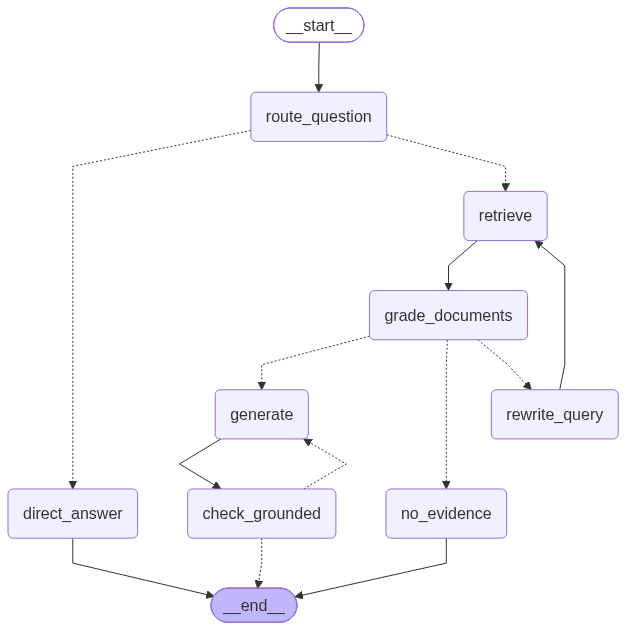

In [28]:
builder = StateGraph(AgentState)
builder.add_node("route_question", route_question_node)
builder.add_node("direct_answer", direct_answer_node)
builder.add_node("retrieve", corrective_retrieve_node)
builder.add_node("grade_documents", grade_documents_node)
builder.add_node("rewrite_query", rewrite_query_node)
builder.add_node("no_evidence", no_evidence_node)
builder.add_node("generate", agent_generate_node)
builder.add_node("check_grounded", check_grounded_node)

builder.add_edge(START, "route_question")
builder.add_conditional_edges("route_question", decide_route)
builder.add_edge("direct_answer", END)

builder.add_edge("retrieve", "grade_documents")
builder.add_conditional_edges("grade_documents", decide_after_grading)
builder.add_edge("rewrite_query", "retrieve")
builder.add_edge("no_evidence", END)

builder.add_edge("generate", "check_grounded")
builder.add_conditional_edges("check_grounded", decide_after_check)

agent_graph = builder.compile()
show_graph(agent_graph)

### 실행 — 질문 유형별로 다른 경로를 타는지 확인

In [29]:
# ① 법률 질문 → 검색 → 평가 → 생성 → 근거 검증
_ = run(agent_graph, "생성형 인공지능 결과물에 대해 사업자는 어떤 표시 의무가 있나요?")

Q. 생성형 인공지능 결과물에 대해 사업자는 어떤 표시 의무가 있나요?
  [route] law
  [retrieve] query = 생성형 인공지능 결과물에 대해 사업자는 어떤 표시 의무가 있나요?
  [grade] 관련 조문 0/1: (없음)
  [retrieve] query = 생성형 인공지능으로 생성된 결과물에 대해 사업자가 부담하는 표시 의무는 무엇인가요?
  [grade] 관련 조문 0/1: (없음)
  [retrieve] query = 생성형 인공지능으로 생성된 결과물에 대해 사업자가 부담하는 표시 의무는 무엇인가요?
  [grade] 관련 조문 0/1: (없음)
경로: route_question → retrieve → grade_documents → rewrite_query → retrieve → grade_documents → rewrite_query → retrieve → grade_documents → no_evidence
근거 조문: (없음)


인공지능기본법에서 관련 근거 조문을 찾지 못했습니다.

In [30]:
# ② 조문 번호를 직접 언급한 질문 (retriever의 Metadata Filter 활용)
_ = run(agent_graph, "제2조에서 정의하는 인공지능사업자는 누구인가요?")

Q. 제2조에서 정의하는 인공지능사업자는 누구인가요?
  [route] law
  [retrieve] query = 제2조에서 정의하는 인공지능사업자는 누구인가요?
  [grade] 관련 조문 0/1: (없음)
  [retrieve] query = 인공지능기본법 제2조의 인공지능사업자 정의 및 해당 요건은 무엇인가요?
  [grade] 관련 조문 0/1: (없음)
  [retrieve] query = 인공지능기본법 제2조의 인공지능사업자 정의 및 해당 요건은 무엇인가요?
  [grade] 관련 조문 0/1: (없음)
경로: route_question → retrieve → grade_documents → rewrite_query → retrieve → grade_documents → rewrite_query → retrieve → grade_documents → no_evidence
근거 조문: (없음)


인공지능기본법에서 관련 근거 조문을 찾지 못했습니다.

In [31]:
# ③ 일반 대화 → 검색 없이 바로 답변
_ = run(agent_graph, "안녕하세요! 무엇을 도와줄 수 있나요?")

Q. 안녕하세요! 무엇을 도와줄 수 있나요?
  [route] general
경로: route_question → direct_answer
근거 조문: (없음)


안녕하세요! 저는 **인공지능기본법 관련 질문**에 답하는 어시스턴트예요.  
법의 내용, 적용 대상, 의무사항, 용어 같은 **인공지능기본법 관련 질문**을 해주시면 도와드릴게요.

원하시면 바로 질문해 주세요!

In [32]:
# ④ 법 범위 밖 질문 → 재작성 루프 후 no_evidence
_ = run(agent_graph, "자율주행차 사고가 나면 보험금은 얼마나 받나요?")

Q. 자율주행차 사고가 나면 보험금은 얼마나 받나요?
  [route] law
  [retrieve] query = 자율주행차 사고가 나면 보험금은 얼마나 받나요?
  [grade] 관련 조문 0/1: (없음)
  [retrieve] query = 자율주행차 사고 시 보험금 지급 기준 및 손해배상 범위는 어떻게 규정되는가
  [grade] 관련 조문 0/1: (없음)
  [retrieve] query = 자율주행차 사고 시 보험금 지급 기준 및 손해배상 범위는 어떻게 규정되는가
  [grade] 관련 조문 0/1: (없음)
경로: route_question → retrieve → grade_documents → rewrite_query → retrieve → grade_documents → rewrite_query → retrieve → grade_documents → no_evidence
근거 조문: (없음)


인공지능기본법에서 관련 근거 조문을 찾지 못했습니다.

In [33]:
# 다른 문제 질문
_ = run(agent_graph, "청년 복지 정책에 대해 설명해줘")

Q. 청년 복지 정책에 대해 설명해줘
  [route] general
경로: route_question → direct_answer
근거 조문: (없음)


안녕하세요! 저는 **인공지능기본법 관련 질의응답**을 도와드리는 어시스턴트예요.  
**인공지능기본법**에 대해 궁금한 점을 질문해 주시면 안내해 드릴 수 있어요.

참고로 **법률·정책·사실 정보**는 직접 답하지 않아요.  
원하시면 **인공지능기본법**에 대해 질문해 주세요.

---
## 정리

| 핵심 LangGraph 개념 | 재사용한 `rag/` 모듈 |
|---------------------|---------------------|
| 입구 라우팅, 출구 자기 검증(Self-RAG), `add_conditional_edges`, `with_structured_output`, `stream` | `retriever.retrieve`, `reranker.rerank`, `chunker.format_article_label` |

**다음 단계**: 노트북에서 검증한 State/노드/그래프를 `langgraph_agent/` 아래 모듈(`state.py`, `nodes.py`, `graph.py`)로 분리하고, FastAPI 엔드포인트에 연결한다.